In [236]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
import bayesflow as bf

In [253]:
import numpy as np 
RNG = np.random.default_rng(2025)

In [276]:
from epydemix import load_predefined_model

# SEIR
def epi_model(transmission_rate, 
              incubation_rate, 
              recovery_rate):
    
    # Load model
    model = load_predefined_model("SEIR", 
                                  transmission_rate = transmission_rate, 
                                  incubation_rate = incubation_rate, 
                                  recovery_rate = recovery_rate)

    # Run it on a given population
    model.set_population(population)
    results = model.run_simulations(start_date="2019-01-01",
                                    end_date="2019-05-07",
                                    #percentage_in_agents= 10 / model.population.Nk.sum(),
                                    Nsim=1)
    return {
        "infected": results.trajectories[0].compartments['Infected_total'],
        "exposed": results.trajectories[0].compartments['Exposed_total'],
        "recovered": results.trajectories[0].compartments['Recovered_total'],
        "susceptible": results.trajectories[0].compartments['Susceptible_total']
    }

In [238]:
def negbin(mean, k):
    mean = np.asarray(mean, dtype=float)
    mean = np.clip(mean, 0.0, None)
    p = k / (k + mean + 1e-8)  # epsilon for safety
    return np.random.negative_binomial(k, p)

In [254]:
from epydemix import load_predefined_model

# SIR
def epi_model(transmission_rate, 
              recovery_rate):
    
    # Load model
    model = load_predefined_model("SIR", 
                                  transmission_rate = transmission_rate, 
                                  recovery_rate = recovery_rate)

    # Run it on a given population
    #model.set_population(population)
    results = model.run_simulations(start_date="2019-01-01",
                                    end_date="2019-05-01",
                                    #percentage_in_agents= 10 / model.population.Nk.sum(),
                                    Nsim=1)
    S_to_I = results.trajectories[0].transitions['Susceptible_to_Infected_total']
    I_to_R = results.trajectories[0].transitions['Infected_to_Recovered_total']
    infected = results.trajectories[0].compartments["Infected_total"]

    return {
        #"S_to_I_obs": negbin(S_to_I, k=3),
        "Infected_obs": negbin(infected, k = 1.1)
        #"I_to_R_obs": negbin(I_to_R, k=1.2)
    }

In [204]:
def epi_model_daily(transmission_rate, recovery_rate):

    model = load_predefined_model(
        "SIR",
        transmission_rate=transmission_rate,
        recovery_rate=recovery_rate
    )

    results = model.run_simulations(
        start_date="2019-01-01",
        end_date="2019-06-01",
        Nsim=1
    )

    S_to_I = results.trajectories[0].transitions[
        'Susceptible_to_Infected_total'
    ]
    I_to_R = results.trajectories[0].transitions[
        'Infected_to_Recovered_total'
    ]

    S_to_I_daily = np.clip(np.diff(S_to_I, prepend=0), 0.0, None)
    I_to_R_daily = np.clip(np.diff(I_to_R, prepend=0), 0.0, None)

    return {
        "S_to_I_obs": negbin(S_to_I_daily, k=5),
        "I_to_R_obs": negbin(I_to_R_daily, k=5)
    }

In [255]:
def priors():
    transmission_rate = RNG.uniform(0.2, 0.45) #(0.30, 0.40)
    #incubation_rate = RNG.uniform(0.05, 0.10)
    recovery_rate = RNG.uniform(0.05, 0.20) #(0.02, 0.07)
    return {
        "transmission_rate": transmission_rate,
        #"incubation_rate": incubation_rate,
        "recovery_rate": recovery_rate
    }

In [256]:
# Perform prior predictive checks
prior_pred_checks = [epi_model(0.30, 0.11) for _ in range(30)]

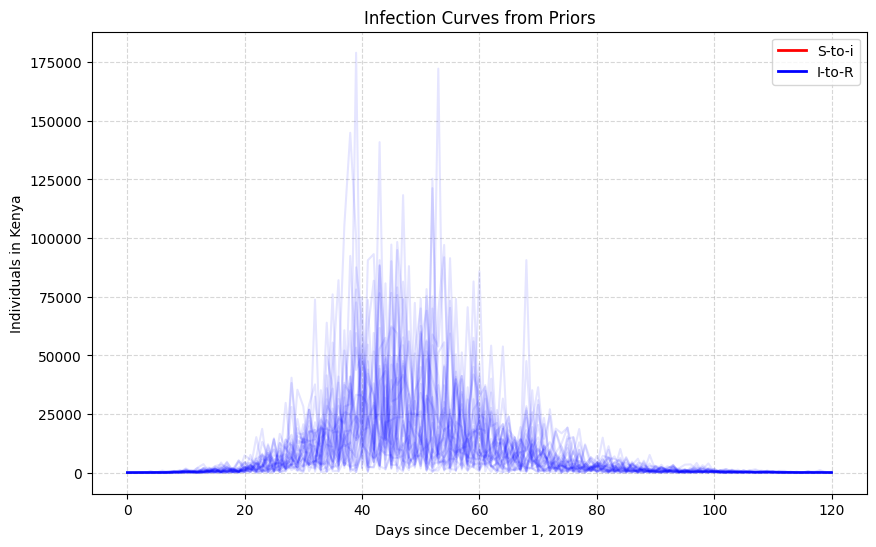

In [266]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Estrazione delle serie temporali
infected = [sim_data["Infected_obs"] for sim_data in prior_pred_checks]
#exposed = [sim_data["exposed"] for sim_data in prior_pred_checks]
#recovered = [sim_data["recovered"] for sim_data in prior_pred_checks]
#susceptible = [sim_data["susceptible"] for sim_data in prior_pred_checks]
#s_to_i = [sim_data["S_to_I_obs"] for sim_data in prior_pred_checks]
#i_to_r = [sim_data["I_to_R_obs"] for sim_data in prior_pred_checks]

plt.figure(figsize=(10, 6))

# Plot della serie 'Exposed' (Arancione)
#for series in exposed:
    #plt.plot(series, alpha=0.1, color="orange")

# Plot della serie 'Infected' (Rosso)
for series in infected:
    plt.plot(series, alpha=0.1, color="blue")

#for series in s_to_i:
    #plt.plot(series, alpha=0.1, color="red")

#for series in i_to_r:
    #plt.plot(series, alpha=0.2, color="blue")
# Plot della serie 'Recovered' (Verde)
#for series in recovered:
    #plt.plot(series, alpha=0.1, color="green")

#for series in susceptible:
    #plt.plot(series, alpha=0.1, color="blue")

# Creazione manuale della legenda per evitare duplicati
legend_elements = [
    Line2D([0], [0], color='red', lw=2, label='S-to-i'),
    Line2D([0], [0], color='blue', lw=2, label='I-to-R'),
    #Line2D([0], [0], color='green', lw=2, label='Recovered'), 
    #Line2D([0], [0], color='blue', lw=2, label='Susceptible')
]
plt.legend(handles=legend_elements, loc='upper right')

plt.title("Infection Curves from Priors")
plt.xlabel("Days since December 1, 2019")
plt.ylabel("Individuals in Kenya")
plt.grid(True, which='both', linestyle='--', alpha=0.5)

# Salvataggio del grafico
plt.savefig("infection_curves.png")

In [258]:
simulator = bf.make_simulator([priors, epi_model])
simulator

In [259]:
adapter = (
    bf.adapters.Adapter()
    .convert_dtype("float64", "float32")
    .as_time_series('Infected_obs')
    #.as_time_series(["S_to_I_obs", "I_to_R_obs"])
    .concatenate(["transmission_rate", "recovery_rate"], into = "inference_variables")
    #.concatenate(["S_to_I_obs","I_to_R_obs"], into = "summary_variables")
    .rename("Infected_obs", "summary_variables")
    .log(["inference_variables", "summary_variables"], p1=True)
)

In [260]:
import keras 

class GRU(bf.networks.SummaryNetwork):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

        self.gru = keras.layers.GRU(64, dropout = 0.1)
        self.summary_stats = keras.layers.Dense(16)
        
    def call(self, time_series, **kwargs):
        """Compresses time_series of shape (batch_size, T, 1) into summaries of shape (batch_size, 8)."""

        summary = self.gru(time_series, training=kwargs.get("stage") == "training")
        summary = self.summary_stats(summary)
        return summary

In [62]:
class MultiHeadSummary(bf.networks.SummaryNetwork):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

        self.cnn = keras.layers.Conv1D(64, 5, activation="relu", padding="causal")

        self.early = keras.layers.GlobalAveragePooling1D()
        self.late  = keras.layers.GlobalMaxPooling1D()

        self.out = keras.layers.Dense(24)

    def call(self, x, **kwargs):
        x = self.cnn(x)
        early = self.early(x[:, :x.shape[1]//3])
        late  = self.late(x[:, x.shape[1]//3:])
        return self.out(keras.layers.Concatenate()([early, late]))

In [77]:
import keras
import tensorflow as tf
import bayesflow as bf

class AttentionSummary(bf.networks.SummaryNetwork):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

        self.norm = keras.layers.Normalization(axis=-1)
        # Temporal feature extractor
        self.cnn = keras.layers.Conv1D(
            filters=64,
            kernel_size=7,
            activation="relu",
            padding="causal"
        )

        # Attention score network
        self.attn = keras.layers.Dense(1)

        # Projection to embedding
        self.out = keras.layers.Dense(24)

    def call(self, x, **kwargs):
        """
        x: (batch, T, 3)  multivariate time series
        """

        x = self.norm(x)
        # Extract temporal features
        h = self.cnn(x)                     # (batch, T, 64)

        # Compute attention scores
        scores = self.attn(h)               # (batch, T, 1)
        weights = tf.nn.softmax(scores, axis=1)

        # Weighted sum over time
        summary = tf.reduce_sum(weights * h, axis=1)  # (batch, 64)

        return self.out(summary)             # (batch, 24)

In [1]:
# Let's check out the new shapes
adapted_sims = adapter(simulator.sample(10))
print(adapted_sims["summary_variables"].shape)
print(adapted_sims["inference_variables"].shape)

NameError: name 'adapter' is not defined

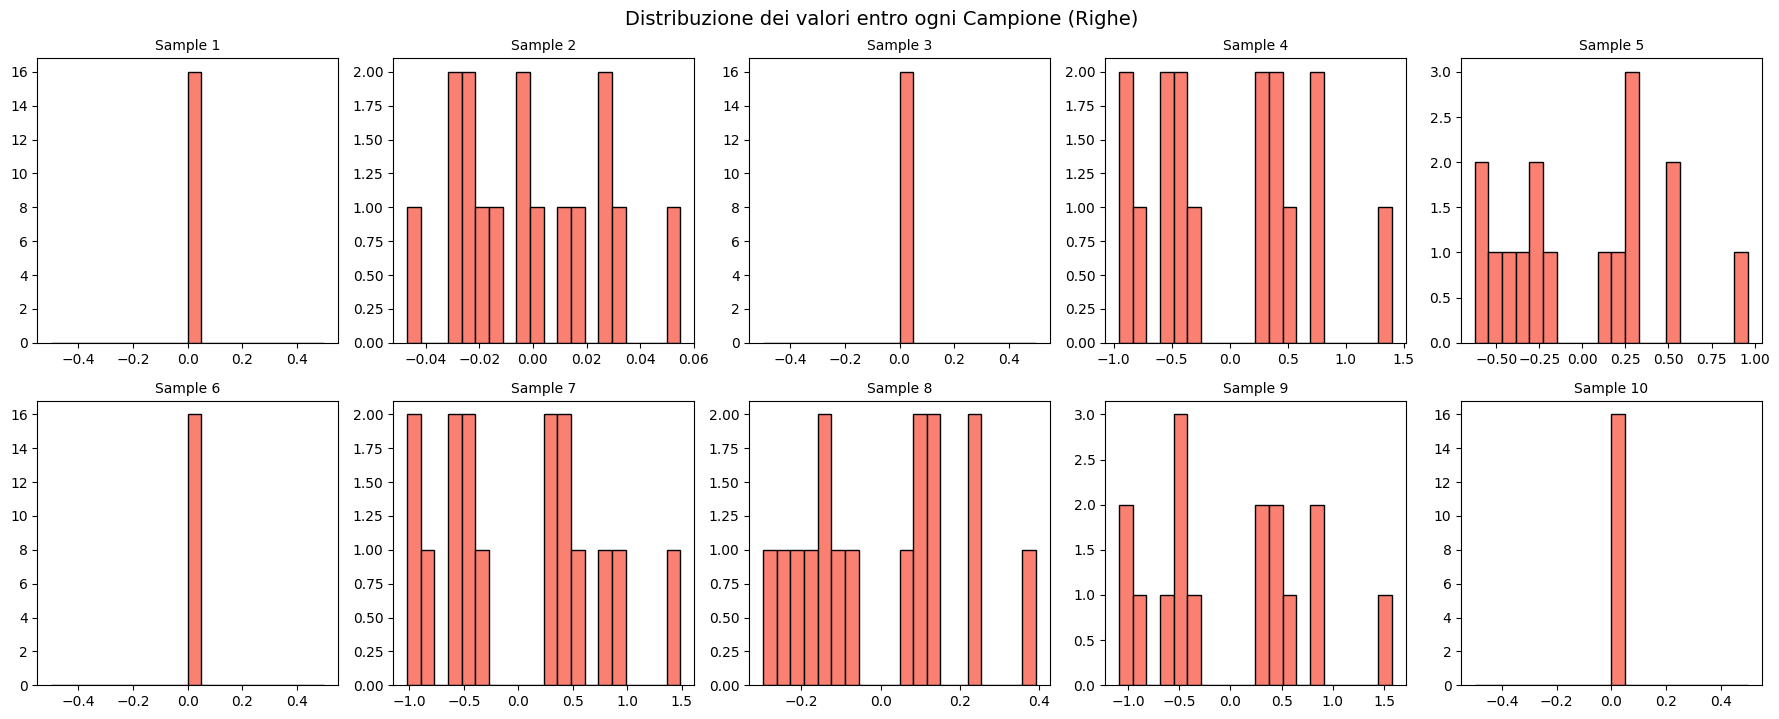

In [263]:
import matplotlib.pyplot as plt
import numpy as np
# Plot dei Campioni separatamente
fig2, axes2 = plt.subplots(2, 5, figsize=(18, 7)) # Per 10 campioni
axes2 = axes2.flatten()

for i in range(out.shape[0]):
    axes2[i].hist(out[i, :], bins=20, color='salmon', edgecolor='black')
    axes2[i].set_title(f'Sample {i+1}', fontsize=10)

plt.tight_layout()
plt.suptitle('Distribuzione dei valori entro ogni Campione (Righe)', fontsize=14, y=1.02)
plt.savefig('sample_distributions.png')

In [264]:
summary_net = GRU()#bf.networks.TimeSeriesNetwork(kernel_sizes = 3) #AttentionSummary() #MultiHeadSummary() #GRU()
inference_net = bf.networks.CouplingFlow()

In [248]:
workflow = bf.BasicWorkflow(
    simulator=simulator,
    adapter=adapter,
    inference_network=inference_net,
    summary_network=summary_net,
    standardize=None # no need to standardize due to log-transform
)

In [38]:
training_data = workflow.simulate(10000)
validation_data = workflow.simulate(500)

In [39]:
history = workflow.fit_offline(
    data = training_data, 
    epochs = 100, 
    batch_size = 64, 
    validation_data = validation_data
)

INFO:bayesflow:Fitting on dataset instance of OfflineDataset.
INFO:bayesflow:Building on a test batch.


Epoch 1/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 59s 136ms/step - loss: -1.2698 - val_loss: -7.0287
Epoch 2/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 21s 133ms/step - loss: -7.0466 - val_loss: -6.9109
Epoch 3/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 23s 145ms/step - loss: -7.2344 - val_loss: -7.2139
Epoch 4/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 29s 182ms/step - loss: -7.4061 - val_loss: -6.7793
Epoch 5/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 29s 186ms/step - loss: -7.2683 - val_loss: -7.5236
Epoch 6/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 29s 187ms/step - loss: -7.3767 - val_loss: -7.2029
Epoch 7/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 30s 189ms/step - loss: -7.4170 - val_loss: -7.5785
Epoch 8/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 29s 186ms/step - loss: -7.7654 - val_loss: -6.6768
Epoch 9/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 30s 188ms/step - loss: -7.6196 - val_loss: -8.1124
Epoch 10/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 27s 170ms/step - loss: -7.6927 - val_loss: -8.1841
Epoch 11/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 23s 145ms/step - loss: -7.7934 - val_

In [265]:
history = workflow.fit_online(epochs = 20, batch_size = 64, num_batches_per_epoch = 50)
# Batch 1: Genera 32 dataset simulati -> Calcola il gradiente -> Aggiorna i parametri.
# Batch 2: Genera altri 32 dataset simulati -> Calcola il gradiente -> Aggiorna i parametri.
# ... e così via fino al ... Batch K. Questa è una epoca

INFO:bayesflow:Fitting on dataset instance of OnlineDataset.


Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 134s 1s/step - loss: -6.7760
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - loss: -6.5790
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - loss: -6.6495
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 50s 989ms/step - loss: -6.2952
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 49s 971ms/step - loss: -6.5996
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 49s 969ms/step - loss: -6.6706
Epoch 7/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - loss: -6.7174
Epoch 8/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - loss: -6.6980
Epoch 9/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 50s 999ms/step - loss: -6.7343
Epoch 10/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 49s 973ms/step - loss: -6.8385
Epoch 11/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 48s 950ms/step - loss: -6.9013
Epoch 12/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 49s 968ms/step - loss: -6.8783
Epoch 13/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - loss: -6.9595
Epoch 14/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 53s 1s/step - loss: -6.9774
Epoch 15/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/ste

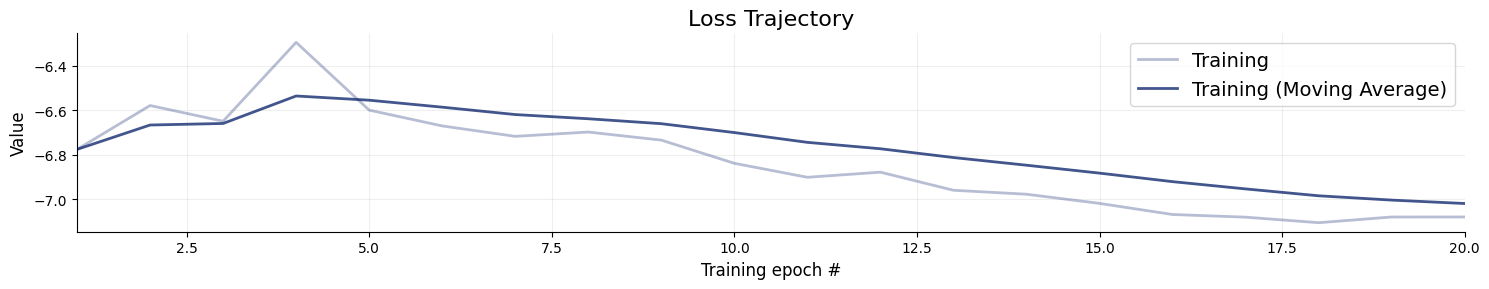

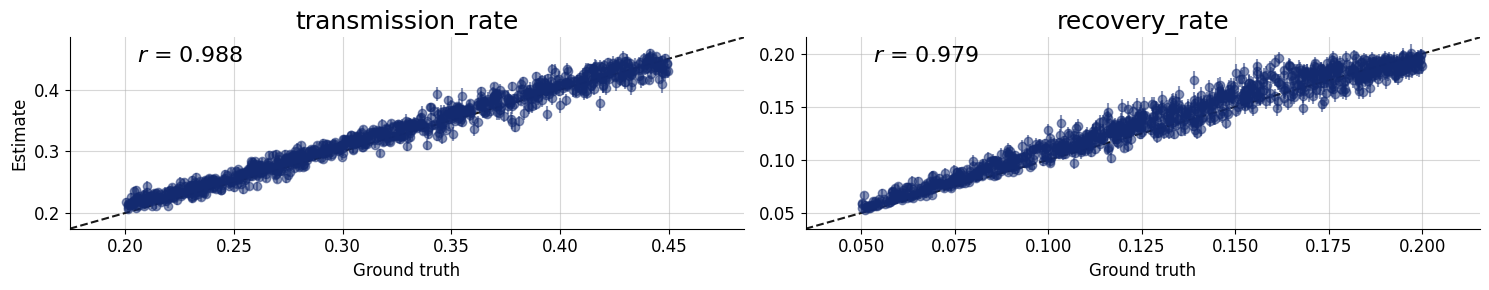

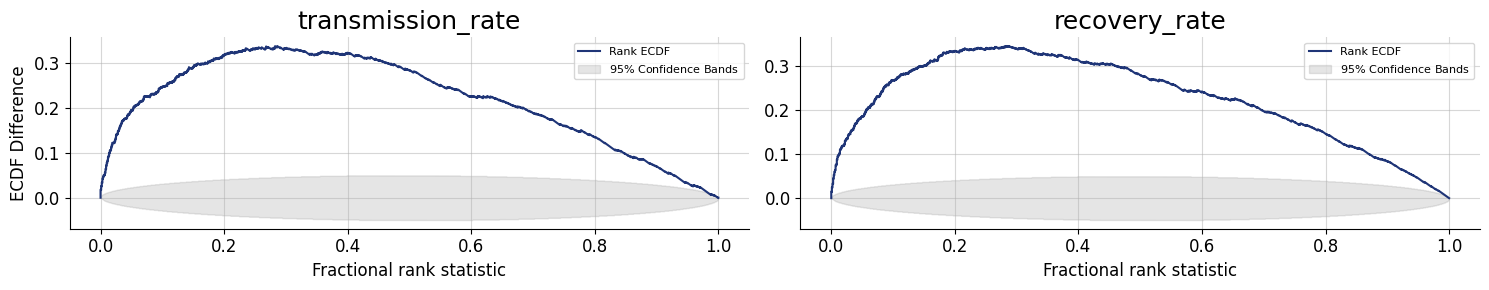

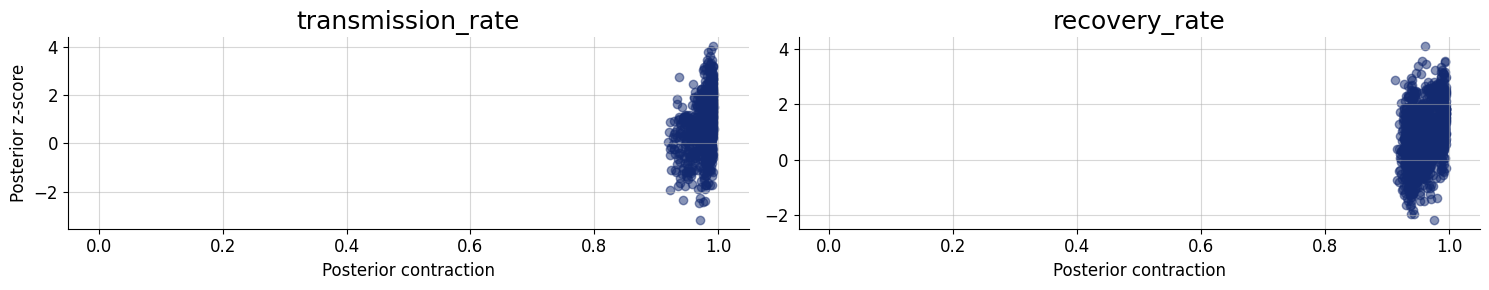

In [268]:
figures = workflow.plot_default_diagnostics(
    test_data = 1000,
    loss_kwargs = {"figsize": (15, 3), "label_fontsize": 12},
    recovery_kwargs = {"figsize": (15, 3), "label_fontsize": 12},
    calibration_ecdf_kwargs = {"figsize": (15, 3), "legend_fontsize": 8, "difference": True, "label_fontsize": 12},
    z_score_contraction_kwargs = {"figsize": (15, 3), "label_fontsize": 12}    
)

In [251]:
metrics = workflow.compute_default_diagnostics(test_data = 500)
metrics

,transmission_rate,recovery_rate
NRMSE,0.073737,0.097513
Posterior Contraction,0.982458,0.959180
Calibration Error,0.138789,0.162368


In [40]:
import seaborn as sns

In [55]:
# Sampling from the posterior
ground_tr = 0.332
ground_rr = 0.11
data = epi_model(ground_tr, ground_rr)

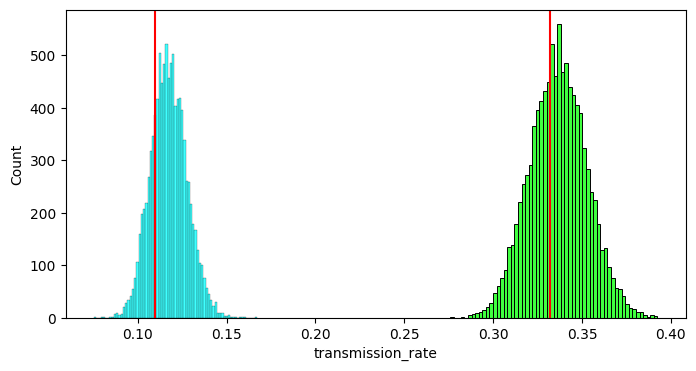

In [56]:
samples = workflow.sample(conditions={"Infected_obs": data['Infected_obs']}, num_samples = 10000)

# Convert into a nice format 2D data frame
samples = workflow.samples_to_data_frame(samples)

plt.figure(figsize = (8, 4))
sns.histplot(samples['transmission_rate'], color = "lime")
sns.histplot(samples['recovery_rate'], color = "cyan")
plt.axvline(x = ground_tr, color = "red")
plt.axvline(x = ground_rr, color = "red")
plt.show()